# LeWAM: a matched experiment on our robotic arm

Compare the **upstream LeWAM model and training loss** with our library implementation on the same `ObstacleArm-v0` trajectories. Both start from identical active weights and train sampled future goals for 50 epochs. This is an owned-environment study, not a reproduction of DMControl Reacher scores.

[Upstream code](https://github.com/MinghaoFu/lewam/tree/f57659fb26858082975794d37a8f3d380ddc1fa7) · [Implementation and experiment details](../../docs/models/jepa/lewam.md)

## 1. Setup

Install `torch-world[lewam,notebooks]`. The default path reads saved progress/results and never trains or commands a physical robot. Rerunning training also requires torchvision and an explicit checkout of the pinned upstream source, supplied through `LEWAM_REFERENCE`.

In [1]:
import json
import os
import sys
from pathlib import Path

if sys.platform == "linux":
    os.environ.setdefault("MUJOCO_GL", "egl")

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import torch_world
from torch_world.benchmarks.lewam_arm_diagnostics import plot_rollout
from torch_world.benchmarks.lewam_matched import train_matched
from torch_world.benchmarks.lewam_study import evaluate_study, prepare_data

ROOT = Path(torch_world.__file__).resolve().parents[1]
REPORTS = ROOT / "examples/action/reports"
OUTPUT = ROOT / "runs/lewam-matched-repeat"
REFERENCE = os.environ.get("LEWAM_REFERENCE")
RUN_TRAINING = False

## 2. Matched training

| Component | Shared setting |
|---|---|
| Data | 128 verified training trajectories; 16 validation trajectories |
| Inputs | Two RGB frames five controls apart; sampled future image goal |
| Architecture | ResNet18/GN16, spatial keypoints, 192-dimensional latents |
| Dynamics / actions | Predict one state at +5 controls; ten-action chunks |
| Schedule | 50 complete epochs, batch 128, five warmup epochs; 4,800 updates per model |
| Initialization | Identical active parameters, from scratch |
| Optimization | AdamW, peak learning rate 0.00015, cosine decay, gradient clipping |
| Precision | Bfloat16 autocast; float32 latent boundary for both models |

The float32 boundary fixes an upstream indexed-write dtype incompatibility with the installed PyTorch version. It preserves gradients through the encoder. Bfloat16 is an upstream-supported option; its default configuration uses float32. The implementations consume random draws differently, so paired seeds do not imply identical stochastic gradients.

The actual upstream encoder, transformer, loss and regularizer are loaded from the supplied source. Both use our shared data sampler, optimizer schedule, environment and tested planning API. This isolates the model/training implementations; it is not an independent reproduction of the entire upstream CLI.

Training: 50/50 epochs recorded
Matched evaluation complete


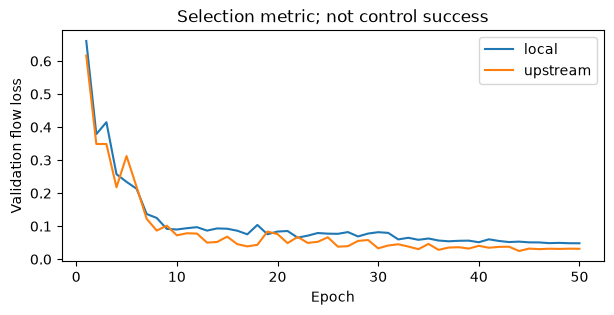

In [2]:
if RUN_TRAINING:
    if not REFERENCE:
        raise ValueError("Set LEWAM_REFERENCE to the pinned upstream checkout before training")
    prepare_data(OUTPUT / "data")
    training = train_matched(
        OUTPUT / "training", OUTPUT / "data/episodes.pt", REFERENCE,
        epochs=50, batch_size=128, precision="bf16", device="cuda",
    )
    result = evaluate_study(OUTPUT / "training", REFERENCE, OUTPUT / "evaluation", cases=50)
    artifact_root = OUTPUT / "evaluation/unseen_trajectories/42/local/0"
else:
    training_path = REPORTS / "lewam-matched-training.json"
    training = json.loads(training_path.read_text()) if training_path.exists() else {}
    result_path = REPORTS / "lewam-matched.json"
    result = json.loads(result_path.read_text()) if result_path.exists() else {}
    artifact_root = REPORTS

ready = bool(result.get("complete"))
print(f"Training: {len(training.get('curve', []))}/{training.get('epochs', 50)} epochs recorded")
print("Matched evaluation complete" if ready else "Matched evaluation pending; no new success result is claimed")
if training.get("curve"):
    fig, ax = plt.subplots(figsize=(7, 3))
    for name in ("local", "upstream"):
        ax.plot([r["epoch"] for r in training["curve"]],
                [r[name]["validation_flow"] for r in training["curve"]], label=name)
    ax.set(xlabel="Epoch", ylabel="Validation flow loss", title="Selection metric; not control success")
    ax.legend()
    plt.show()

## 3. Environment and coverage

Physics, torque limits and native success tolerances stay fixed. A render-only marker preserves the collection target in current and goal images. The scored target is the sampled future arm pose. Trajectory replay and goal rendering are checked independently of learned performance.

A **separate coverage dataset** adds reverse approaches, corrections on both sides of the goal, and braking from nonzero velocity. All 128 training and 16 validation demonstrations held native success over their final ten recorded states. This dataset has not been used by the matched baseline models. To run a subsequent coverage comparison, call `prepare_data(path, diverse_motion=True)` and pass its `episodes.pt` to the same trainer.

In [3]:
coverage_path = REPORTS / "lewam-matched-coverage.json"
if coverage_path.exists():
    coverage = json.loads(coverage_path.read_text())
    for split, held in coverage["ten_frame_hold"].items():
        print(f"Diverse data · {split}: {sum(held)}/{len(held)} final ten-frame holds")
replay_path = REPORTS / "lewam-matched-replay.json"
if replay_path.exists():
    replay = json.loads(replay_path.read_text())["replay"]
    display(Markdown(
        "| Replay check | Maximum error |\n|---|---:|\n"
        f"| State | {max(r['max_state_error'] for r in replay):.2g} |\n"
        f"| Pixels (uint8) | {max(r['max_pixel_error_uint8'] for r in replay):.2g} |\n"
        f"| State changed by goal rendering | {max(r['goal_render_state_error'] for r in replay):.2g} |"
    ))

Diverse data · train: 128/128 final ten-frame holds
Diverse data · validation: 16/16 final ten-frame holds


| Replay check | Maximum error |
|---|---:|
| State | 0 |
| Pixels (uint8) | 0 |
| State changed by goal rendering | 0 |

## 4. Reaching, settling and holding

Evaluation uses 50 cases for each of seeds **42, 0 and 1**, separately on training trajectories and unseen trajectories. Starts are sampled across the eligible trajectory; goals are 25 controls later, with a 50-control budget. Models share exactly the same tasks. Each planner uses 32 proposals and five Adam refinements, executing five controls before replanning.

**Pose reached** ignores velocity. **Native reached** also requires settling. **Final** checks native success at the last step; **hold** requires it throughout the final ten controls. Initial pose successes are shown explicitly, with a separate score for initially unsatisfied tasks. Our pose tolerance is not the identical DMControl criterion.

Direct policy, planned policy and shuffled-goal planning are learned controllers. Expert and zero-control baselines check feasibility and passive motion; neither intervenes in learned control.

In [4]:
if ready:
    rows = ["| Split | Model / controller | Initial pose | Pose reached | Native reached | Final | Hold |",
            "|---|---|---:|---:|---:|---:|---:|"]
    for split, models in result["summary"].items():
        for model, controllers in models.items():
            for controller, scores in controllers.items():
                if model == "upstream" and controller in ("expert", "zero"):
                    continue  # Shared baseline trials, already displayed once.
                n = scores["count"]
                values = " | ".join(f"{scores[k]}/{n}" for k in
                    ("pose_initial_success", "pose_success", "success", "final_success", "hold_success"))
                rows.append(f"| {split} | {model} / {controller} | {values} |")
    display(Markdown("\n".join(rows)))
    rows = ["| Split | Model / controller | Pose hits from initially unsatisfied tasks |", "|---|---|---:|"]
    for split, models in result["summary"].items():
        for model, controllers in models.items():
            for controller in ("policy", "planner", "shuffled_goal_planner"):
                s = controllers[controller]["initially_pose_unsatisfied"]
                rows.append(f"| {split} | {model} / {controller} | {s['pose_success']}/{s['count']} |")
    display(Markdown("\n".join(rows)))
else:
    display(Markdown("**Evaluation is pending.** Earlier pilot scores are not substituted for this study."))

| Split | Model / controller | Initial pose | Pose reached | Native reached | Final | Hold |
|---|---|---:|---:|---:|---:|---:|
| training_trajectories | local / policy | 65/150 | 149/150 | 138/150 | 81/150 | 81/150 |
| training_trajectories | local / planner | 65/150 | 146/150 | 120/150 | 15/150 | 15/150 |
| training_trajectories | local / shuffled_goal_planner | 65/150 | 139/150 | 92/150 | 1/150 | 1/150 |
| training_trajectories | local / expert | 65/150 | 150/150 | 150/150 | 150/150 | 148/150 |
| training_trajectories | local / zero | 65/150 | 72/150 | 71/150 | 0/150 | 0/150 |
| training_trajectories | upstream / policy | 65/150 | 149/150 | 140/150 | 99/150 | 99/150 |
| training_trajectories | upstream / planner | 65/150 | 145/150 | 116/150 | 8/150 | 8/150 |
| training_trajectories | upstream / shuffled_goal_planner | 65/150 | 138/150 | 91/150 | 2/150 | 1/150 |
| unseen_trajectories | local / policy | 60/150 | 147/150 | 136/150 | 84/150 | 84/150 |
| unseen_trajectories | local / planner | 60/150 | 141/150 | 110/150 | 8/150 | 7/150 |
| unseen_trajectories | local / shuffled_goal_planner | 60/150 | 134/150 | 89/150 | 7/150 | 5/150 |
| unseen_trajectories | local / expert | 60/150 | 150/150 | 150/150 | 150/150 | 148/150 |
| unseen_trajectories | local / zero | 60/150 | 65/150 | 62/150 | 0/150 | 0/150 |
| unseen_trajectories | upstream / policy | 60/150 | 147/150 | 135/150 | 89/150 | 89/150 |
| unseen_trajectories | upstream / planner | 60/150 | 142/150 | 107/150 | 9/150 | 9/150 |
| unseen_trajectories | upstream / shuffled_goal_planner | 60/150 | 129/150 | 80/150 | 1/150 | 0/150 |

| Split | Model / controller | Pose hits from initially unsatisfied tasks |
|---|---|---:|
| training_trajectories | local / policy | 84/85 |
| training_trajectories | local / planner | 81/85 |
| training_trajectories | local / shuffled_goal_planner | 74/85 |
| training_trajectories | upstream / policy | 84/85 |
| training_trajectories | upstream / planner | 80/85 |
| training_trajectories | upstream / shuffled_goal_planner | 73/85 |
| unseen_trajectories | local / policy | 87/90 |
| unseen_trajectories | local / planner | 81/90 |
| unseen_trajectories | local / shuffled_goal_planner | 74/90 |
| unseen_trajectories | upstream / policy | 87/90 |
| unseen_trajectories | upstream / planner | 82/90 |
| unseen_trajectories | upstream / shuffled_goal_planner | 69/90 |

## 5. Does the world model choose useful actions?

The prediction audit compares identical recorded/perturbed action sequences in both models at **5, 10 and 25 controls**. It measures latent prediction error, action-ranking agreement with actual pose distance, and selection regret relative to the best tested candidate. Tied candidate pairs are excluded from ranking agreement.

Ranking actual future images tests the visual distance metric; ranking imagined future images additionally tests learned dynamics. These are diagnostic candidate sets, not proof of global planning accuracy. The audit uses validation episodes and does not select checkpoints.

In [5]:
if ready:
    rows = ["| Controls | Model | Variance-normalized prediction MSE | Predicted ranking agreement | Actual-image ranking agreement | Selection regret |",
            "|---:|---|---:|---:|---:|---:|"]
    def mean_valid(values):
        valid = [x for x in values if x is not None]
        return sum(valid) / len(valid) if valid else float("nan")
    for horizon, models in result["prediction_audit"]["horizons"].items():
        for name, metrics in models.items():
            predicted = metrics["predicted_ranking"]
            actual = metrics["encoded_actual_ranking"]
            rows.append(f"| {horizon} | {name} | {metrics['variance_normalized_mse']:.3f} | "
                        f"{mean_valid(predicted['pairwise_agreement']):.3f} | "
                        f"{mean_valid(actual['pairwise_agreement']):.3f} | "
                        f"{mean_valid(predicted['selection_regret']):.3f} |")
    display(Markdown("\n".join(rows)))
else:
    print("Prediction diagnostics will be displayed after matched evaluation completes.")

| Controls | Model | Variance-normalized prediction MSE | Predicted ranking agreement | Actual-image ranking agreement | Selection regret |
|---:|---|---:|---:|---:|---:|
| 5 | local | 1.142 | 0.750 | 0.772 | 0.485 |
| 5 | upstream | 1.165 | 0.679 | 0.830 | 0.759 |
| 10 | local | 1.296 | 0.737 | 0.848 | 1.062 |
| 10 | upstream | 1.308 | 0.746 | 0.844 | 0.600 |
| 25 | local | 1.567 | 0.737 | 0.804 | 0.000 |
| 25 | upstream | 1.535 | 0.732 | 0.817 | 0.000 |

## 6. Inspect the first unseen rollout and interpret the comparison

The video uses the **first unseen task for evaluation seed 42**, selected without inspecting success. Left: current observation; right: goal. The action plot compares commands with expert labels at the states actually visited. Those labels never control the learned rollout.

If both implementations fail similarly, focus next on demonstration coverage and the learned distance/dynamics rather than assuming a local model bug. If upstream performs materially better, isolate the remaining implementation differences before changing the task. A reaching advantage does not establish sustained holding, and neither result qualifies SO101 hardware execution.

This study uses one shared model initialization. The three evaluation seeds measure task-sampling variation, not variation across independently trained models. No near-100% result is guaranteed.

First unseen rollout · seed 50017


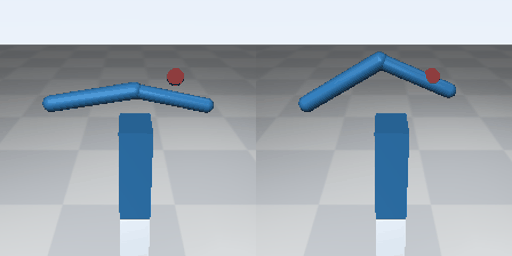

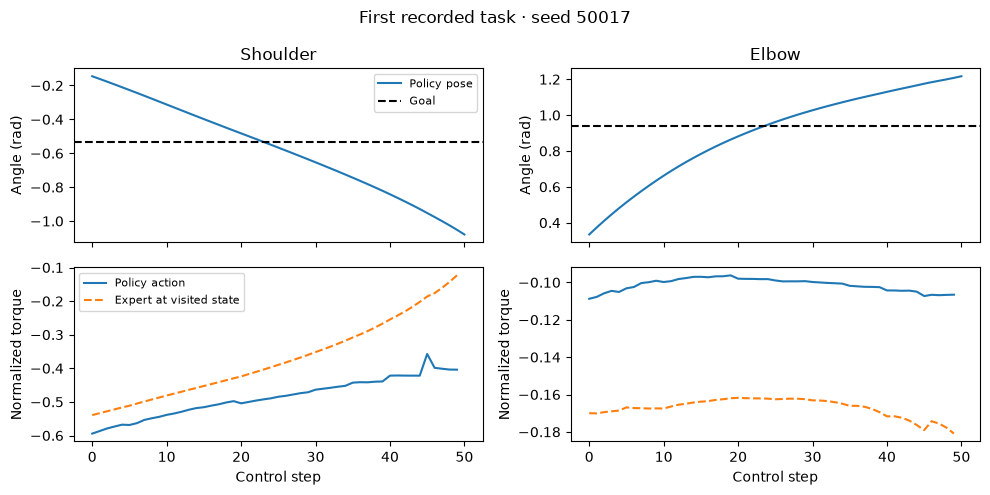

Simulation only; no physical-robot commands were issued.


In [6]:
if ready:
    trace_path = artifact_root / ("trace-planner.json" if RUN_TRAINING else "lewam-matched-trace.json")
    video_path = artifact_root / ("rollout.gif" if RUN_TRAINING else "lewam-matched.gif")
    trace = json.loads(trace_path.read_text())
    print(f"First unseen rollout · seed {trace['seeds'][0]}")
    display(Image(filename=str(video_path)))
    plot_rollout(trace)
    plt.show()
else:
    print("Full study still running. No new rollout or completed-result interpretation is available yet.")
print("Simulation only; no physical-robot commands were issued.")